<a href="https://colab.research.google.com/drive/1tnOvFNgXiLtktiSsltTr0s308LZSsEPJ">Abre este Jupyter en Google Colab</a>

# Regresión Lineal: Coste de un incidente de seguridad

Fundamentos básicos para la regresión lineal, demostrado en un caso de uso sencillo relacionado con la Ciberseguridad.

### 0. Imports

In [7]:
# Instalacion de librerías externas
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install scikit-learn

### 1. Generación del conjunto de datos

Se genera un conjunto de datos aleatorio para simular:
- `X`: Número de equipos afectados en un incidente de seguridad
- `y`: Coste del incidente de seguridad

El objetivo es crear un conjunto de datos que refleje escenarios realistas de incidentes.

In [9]:
import numpy as np

X = 2 * np.random.rand(75, 1)
y = 4 + 3 * X + np.random.randn(75, 1)

print("La longitud del conjunto de datos es:", len(X))

La longitud del conjunto de datos es: 75


### 2. Visualización del conjunto de datos

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

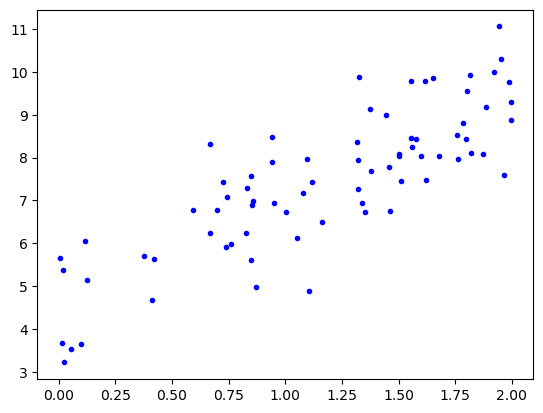

In [12]:
plt.plot(X, y, "b.")
plt.show()

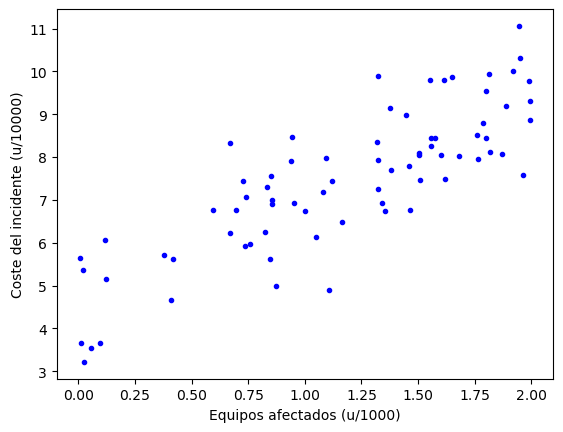

In [13]:
plt.plot(X, y, "b.")
plt.xlabel("Equipos afectados (u/1000)")
plt.ylabel("Coste del incidente (u/10000)")
plt.show()

### 3. Modificación del conjunto de datos

In [15]:
import pandas as pd

In [16]:
data = {'n_equipos_afectados': X.flatten(), 'coste': y.flatten()}
df = pd.DataFrame(data)
df.head(10)

,n_equipos_afectados,coste
0,1.374711,9.133125
1,0.853722,6.899091
2,1.785532,8.801839
3,1.619734,7.483441
4,1.764225,7.958662
5,1.987760,9.774826
6,1.380408,7.691389
7,0.943172,8.476084
8,1.105659,4.884838
9,1.995836,8.869940


In [17]:
# Escalado del número de equipos afectados
df['n_equipos_afectados'] = df['n_equipos_afectados'] * 1000
df['n_equipos_afectados'] = df['n_equipos_afectados'].astype('int')
# Escalado del coste
df['coste'] = df['coste'] * 10000
df['coste'] = df['coste'].astype('int')
df.head(10)

,n_equipos_afectados,coste
0,1374,91331
1,853,68990
2,1785,88018
3,1619,74834
4,1764,79586
5,1987,97748
6,1380,76913
7,943,84760
8,1105,48848
9,1995,88699


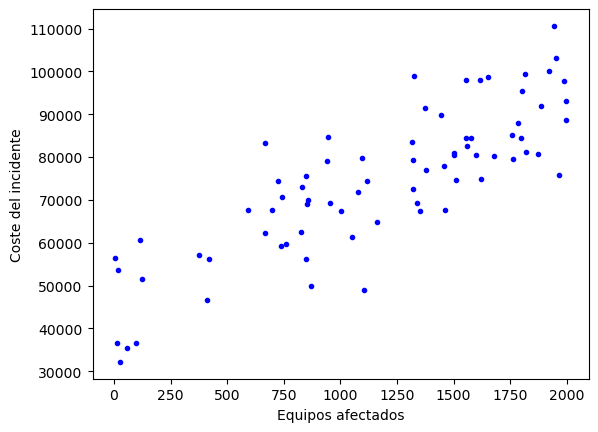

In [18]:
# Representación gráfica del conjunto de datos
plt.plot(df['n_equipos_afectados'], df['coste'], "b.")
plt.xlabel("Equipos afectados")
plt.ylabel("Coste del incidente")
plt.show()

## 4. Creación del Modelo de Regresión Lineal
En este paso se entrena el modelo de regresión lineal utilizando `sklearn`.
El objetivo es aprender la relación entre:
- `X`: Equipos afectados
- `y`: Coste del incidente de seguridad

In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
# Construcción del modelo y ajuste de la función hipótesis
lin_reg = LinearRegression()
lin_reg.fit(df['n_equipos_afectados'].values.reshape(-1, 1), df['coste'].values)

LinearRegression()

In [22]:
# Parámetro theta 0
lin_reg.intercept_

45967.22896898923

In [23]:
# Parámetro theta 1
lin_reg.coef_

array([24.22757763])

In [24]:
# Predicción para el valor mínimo y máximo del conjunto de datos de entrenamiento
X_min_max = np.array([[df["n_equipos_afectados"].min()], [df["n_equipos_afectados"].max()]])
y_train_pred = lin_reg.predict(X_min_max)

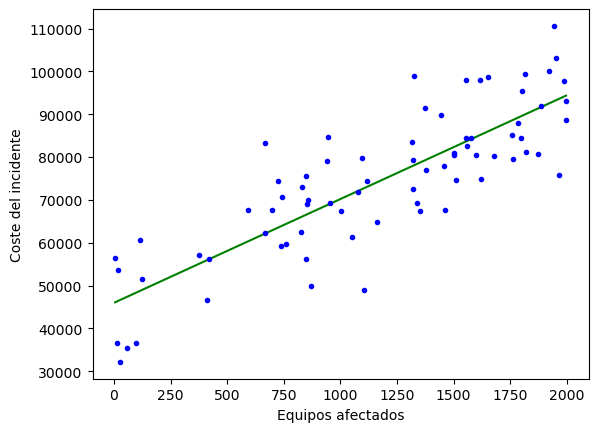

In [25]:
# Representación gráfica de la función hipótesis generada
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(df['n_equipos_afectados'], df['coste'], "b.")
plt.xlabel("Equipos afectados")
plt.ylabel("Coste del incidente")
plt.show()

## 5. Predicción y Visualización del Modelo

Se utilizan los datos de entrada (`X`) para predecir el coste del incidente (`y_pred`) utilizando el modelo entrenado.
Se visualiza la línea de regresión junto con los datos originales para evaluar el ajuste del modelo.


In [27]:
x_new = np.array([[1300]]) # 1300 equipos afectados

# Predicción del coste que tendría el incidente
coste = lin_reg.predict(x_new) 

print("El coste del incidente sería:", int(coste[0]), "€")

El coste del incidente sería: 77463 €


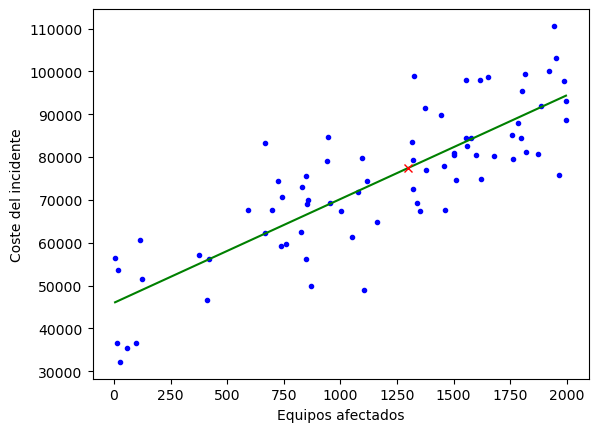

In [28]:
plt.plot(df['n_equipos_afectados'], df['coste'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, coste, "rx")
plt.xlabel("Equipos afectados")
plt.ylabel("Coste del incidente")
plt.show()

In [29]:
x_new = np.array([[1100]]) # 1300 equipos afectados

# Predicción del coste que tendría el incidente
coste = lin_reg.predict(x_new) 

print("El coste del incidente sería:", int(coste[0]), "€")

El coste del incidente sería: 72617 €


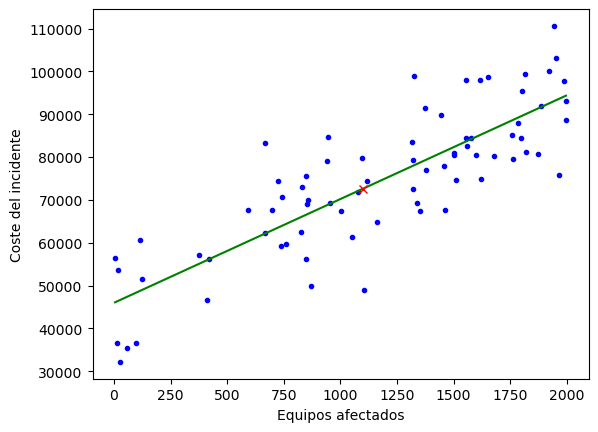

In [30]:
plt.plot(df['n_equipos_afectados'], df['coste'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, coste, "rx")
plt.xlabel("Equipos afectados")
plt.ylabel("Coste del incidente")
plt.show()

In [ ]:
x2_new = np.array([[1300]]) # 1300 equipos afectados

# Predicción del coste que tendría el incidente
coste2 = lin_reg.predict(x2_new)

print("El coste del incidente sería:", int(coste2[0]), "€")

El coste del incidente sería: 89576 €


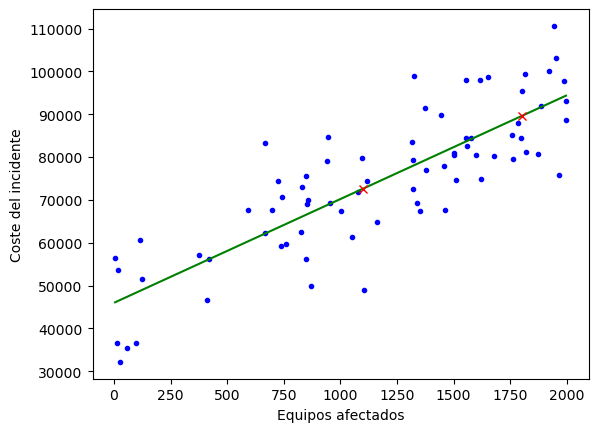

In [32]:
plt.plot(df['n_equipos_afectados'], df['coste'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, coste, "rx")
plt.plot(x2_new, coste2, "rx")
plt.xlabel("Equipos afectados")
plt.ylabel("Coste del incidente")
plt.show()